# Selection refinement 2 — CVaR (tail-loss) sizing

**Question.** v3.1 sizes each held name ∝ 1/basis_vol. Basis-vol is a **symmetric** risk measure on
only the basis leg. Would sizing by a **downside tail** measure of the *whole* pair return do better?

**Hypothesis.** The delta-neutral pair return is `funding + basis`. The thing that actually hurts is a
fat **left tail** — a basis blowout, or funding compressing/flipping. Inverse-basis-vol underweights
volatile-basis names but is blind to (a) the funding tail and (b) the asymmetry (it penalizes upside
dispersion equally). Sizing ∝ 1/CVaR — inverse expected tail loss — should target the risk we care about.

**Method.** Per name, point-in-time **CVaR₅%** = mean of the worst 5% of its own **daily pair returns**
(`R = F + L`, the per-name book `lab` already produces) over a rolling window (60d and 120d; then sweep
30-120d). Weight ∝ 1/(−CVaR), winsorized cross-sectionally (a name with a near-zero tail must not
explode the book). This replaces inv-basis-vol inside the otherwise-unchanged v3.1 stack; deadband 0.5
kept. Also a **50/50 blend** with inv-basis-vol. In-sample + temporal OOS (pick window on train
2021-2023, freeze, read test 2024-2026). All via `lab.py` (engine parity 1e-6).

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
import sys; from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import research.funding_carry.lab as H
from src.common import config as cfg
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','0.6'
COSTS = cfg.load_config('strategies/funding_carry/v3.1.yaml')['costs']
maj, non = H.universe(); MAJ = set(maj); P = H.load_panels(maj + non)
F, E, didx, syms = P['F'], P['E'], P['didx'], P['symbols']; R = P['R']
SPECS = [{'name':'funding_vol','window':30},{'name':'neg_freq','window':30},{'name':'basis','window':30}]
VETO  = [{'feature':'funding_vol','direction':'max','cap':0.75},
         {'feature':'neg_freq','direction':'max','cap':0.40},
         {'feature':'basis','direction':'max','cap':0.01}]
feats = H.feature_panels(P, SPECS + [{'name':'basis_vol','window':30}]); bvol = feats['basis_vol']
invvol = 1.0 / bvol.replace(0.0, np.nan)
apr = H.signal_apr(F, 7).reindex(index=didx, columns=syms).where(E)

def cvar_panel(window, q=0.05):
    """Point-in-time CVaR: rolling mean of the worst q-fraction of a name's daily pair returns R."""
    k = max(1, int(round(q*window)))
    def f(x):
        x = x[~np.isnan(x)]
        return np.sort(x)[:k].mean() if len(x) >= window//2 else np.nan
    return R.rolling(window, min_periods=window//2).apply(f, raw=True)

def cvar_size(window, clip=0.90):
    cv = cvar_panel(window); s = (1.0/(-cv)).where(cv < 0)      # CVaR<0 (a loss); size = inverse tail loss
    return s.clip(upper=s.quantile(clip, axis=1), axis=0)       # winsorize the thin-tail names day-by-day

def v31_book(size, band=0.5, mask=None):
    """v3.1 stack with the size vector swapped (a name we can't size isn't held — engine parity)."""
    veto_ok = H.veto_mask(feats, VETO, apr) & size.notna() & (size > 0)
    Hh = H.held_matrix(apr, veto_ok, 0.08, 0.02, None, None)
    W = H.deadband_weights(H.weights_from_held(Hh, size), band)
    return H.book(W, P, COSTS, mask=mask, warmup_days=30)

def blend_book(size_a, size_b, band=0.5, mask=None):
    """50/50 blend of two size schemes: average the normalized held-weights, renormalize, deadband."""
    veto_ok = H.veto_mask(feats, VETO, apr) & size_a.notna() & (size_a>0) & size_b.notna() & (size_b>0)
    Hh = H.held_matrix(apr, veto_ok, 0.08, 0.02, None, None)
    wa, wb = H.weights_from_held(Hh, size_a), H.weights_from_held(Hh, size_b)
    w = 0.5*wa + 0.5*wb; w = w.div(w.sum(axis=1).replace(0,1), axis=0)
    return H.book(H.deadband_weights(w, band), P, COSTS, mask=mask, warmup_days=30)

def kpi(res):
    a,b = res['1.0x'], res['2.0x']
    return {'net%':round(a['ann_return']*100,2),'Sharpe':round(a['sharpe'],2),
            'net@2x%':round(b['ann_return']*100,2),'Sh@2x':round(b['sharpe'],2),
            'maxDD%':round(a['max_drawdown']*100,2),'Calmar':round(a['ann_return']/abs(a['max_drawdown']),1),
            'CVaR95':round(a['cvar95']*100,3),'turn':round(a['ann_turnover'],1)}
def eq(res): return res['net'].cumsum()*100

base = v31_book(invvol)                                          # v3.1 = inverse-basis-vol
V31 = H.evaluate_select(P,7,0.08,0.02,None,None,COSTS,feature_specs=SPECS,veto_rules=VETO,
                        size_kind='inv_basis_vol',band=0.5,warmup_days=30)
assert abs(base['1.0x']['sharpe'] - V31['1.0x']['sharpe']) < 1e-9, 'parity break'
print('parity OK. v3.1 baseline (inv-basis-vol):', kpi(base))

parity OK. v3.1 baseline (inv-basis-vol): {'net%': 9.94, 'Sharpe': 6.32, 'net@2x%': 6.05, 'Sh@2x': 3.62, 'maxDD%': -2.8, 'Calmar': 3.5, 'CVaR95': -0.103, 'turn': 20.5}


## 1. What CVaR sees that basis-vol doesn't

CVaR is the average of a name's *worst days*. Below: for a clean major (BTC) and a couple of
higher-tail alts, the rolling 60d CVaR₅% (a negative number — the typical bad-day loss). The majors sit
near zero; the alts show episodic deep tails that basis-vol, being symmetric, only partly reflects.
Inverse-CVaR therefore penalizes exactly the names whose *downside* is fat.

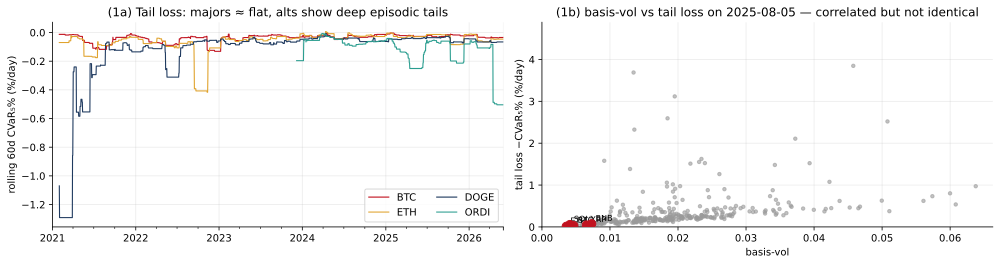

In [2]:
cv60 = cvar_panel(60)
fig,(a1,a2) = plt.subplots(1,2,figsize=(14,3.8))
show = [m for m in ['btcusdt','ethusdt'] if m in syms] + [s for s in ['dogeusdt','ordiusdt','wifusdt','pepeusdt'] if s in syms][:2]
for s,c in zip(show, [RED,AMBER,NAVY,TEAL]):
    (cv60[s]*100).plot(ax=a1, lw=1.1, color=c, label=s.replace('usdt','').upper())
a1.set_ylabel('rolling 60d CVaR₅% (%/day)'); a1.legend(ncol=2); a1.set_title('(1a) Tail loss: majors ≈ flat, alts show deep episodic tails')
# CVaR vs basis-vol across names on a snapshot: they rank-agree loosely but diverge in the tail
day = cv60[(cv60.notna()).sum(axis=1) >= 100].index[-300]
x = bvol.loc[day]; y = -cv60.loc[day]; ok = x.notna() & y.notna() & (y>0)
a2.scatter(x[ok], y[ok]*100, s=12, color=GREY, alpha=0.6)
for s in [m for m in maj if ok.get(s,False)]:
    a2.scatter(x[s], -cv60.loc[day,s]*100, s=70, color=RED, zorder=5)
    a2.annotate(s.replace('usdt','').upper(),(x[s],-cv60.loc[day,s]*100),fontsize=8,xytext=(4,3),textcoords='offset points')
a2.set_xlabel('basis-vol'); a2.set_ylabel('tail loss −CVaR₅% (%/day)')
a2.set_xlim(0,np.nanpercentile(x[ok],95)); a2.set_ylim(0,np.nanpercentile(y[ok]*100,95))
a2.set_title(f'(1b) basis-vol vs tail loss on {day.date()} — correlated but not identical'); plt.tight_layout(); plt.show()

## 2. Where the two weightings actually differ

The required check: plot each held name's **inverse-CVaR weight vs its inverse-basis-vol weight** on a
snapshot day. Names on the 45° line get the same weight either way; names *above* it are ones CVaR
likes more than basis-vol (low tail relative to their basis dispersion) and *below* are ones CVaR
distrusts (fat tail hiding behind modest basis-vol). The scatter shows the reweighting is targeted, not
a global rescale.

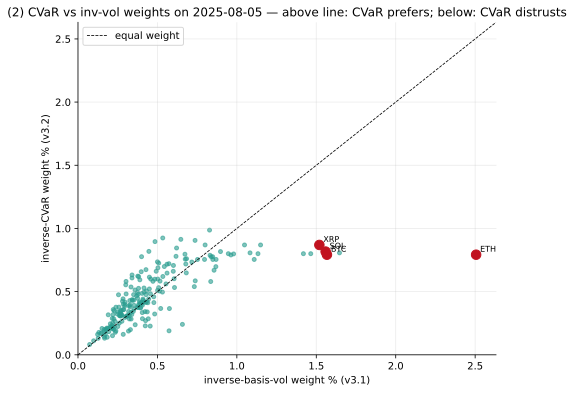

In [3]:
W_iv = base['W']; W_cv = v31_book(cvar_size(60))['W']
held = W_cv.columns[(W_cv.loc[day] > 0) & (W_iv.loc[day] > 0)]
xi = W_iv.loc[day, held]*100; yc = W_cv.loc[day, held]*100
fig,ax = plt.subplots(figsize=(7.5,6))
ax.scatter(xi, yc, s=16, color=TEAL, alpha=0.6)
lim = max(xi.max(), yc.max())*1.05
ax.plot([0,lim],[0,lim],color='k',lw=0.8,ls='--',label='equal weight')
for s in [m for m in maj if m in held]:
    ax.scatter(W_iv.loc[day,s]*100, W_cv.loc[day,s]*100, s=90, color=RED, zorder=5)
    ax.annotate(s.replace('usdt','').upper(),(W_iv.loc[day,s]*100,W_cv.loc[day,s]*100),fontsize=8,xytext=(4,3),textcoords='offset points')
ax.set_xlabel('inverse-basis-vol weight % (v3.1)'); ax.set_ylabel('inverse-CVaR weight % (v3.2)')
ax.set_xlim(0,lim); ax.set_ylim(0,lim); ax.legend()
ax.set_title(f'(2) CVaR vs inv-vol weights on {day.date()} — above line: CVaR prefers; below: CVaR distrusts'); plt.show()

## 3. Does it pay? in-sample + temporal OOS

Swap inv-basis-vol → inverse-CVaR (60d and 120d) and the 50/50 blend, everything else v3.1. Report full
sample plus the train/test split. The 60d CVaR and the 60d blend **beat the baseline on net Sharpe,
2×-cost Sharpe, maxDD and turnover** — and hold up out-of-sample.

In [4]:
cv60s, cv120s = cvar_size(60), cvar_size(120)
tr = H._window_mask(didx, end='2023-12-31'); te = H._window_mask(didx, start='2024-01-01')
def three(builder):
    return {**{f'IS {k}':v for k,v in kpi(builder(None)).items() if k in ('Sharpe','Sh@2x','net%','maxDD%','turn')},
            'trainSh':round(builder(tr)['1.0x']['sharpe'],2),
            'TEST Sh':round(builder(te)['1.0x']['sharpe'],2),'TEST 2x':round(builder(te)['2.0x']['sharpe'],2),
            'TEST DD%':round(builder(te)['1.0x']['max_drawdown']*100,2)}
tab = {
 'v3.1 inv-basis-vol':    three(lambda m: v31_book(invvol, mask=m)),
 'CVaR 120d':             three(lambda m: v31_book(cv120s, mask=m)),
 'CVaR 60d':              three(lambda m: v31_book(cv60s, mask=m)),
 'CVaR 60d / inv-vol 50-50': three(lambda m: blend_book(cv60s, invvol, mask=m)),
}
print(pd.DataFrame(tab).T.to_string())

                          IS net%  IS Sharpe  IS Sh@2x  IS maxDD%  IS turn  trainSh  TEST Sh  TEST 2x  TEST DD%
v3.1 inv-basis-vol           9.94       6.32      3.62      -2.80     20.5     6.25     7.52     4.32     -0.56
CVaR 120d                    8.59       6.25      3.67      -2.46     16.6     5.83     7.32     5.15     -0.42
CVaR 60d                    10.02       6.38      3.93      -2.52     18.6     6.27     7.73     5.19     -0.41
CVaR 60d / inv-vol 50-50    10.01       6.46      3.97      -2.65     18.6     6.30     8.02     5.36     -0.40


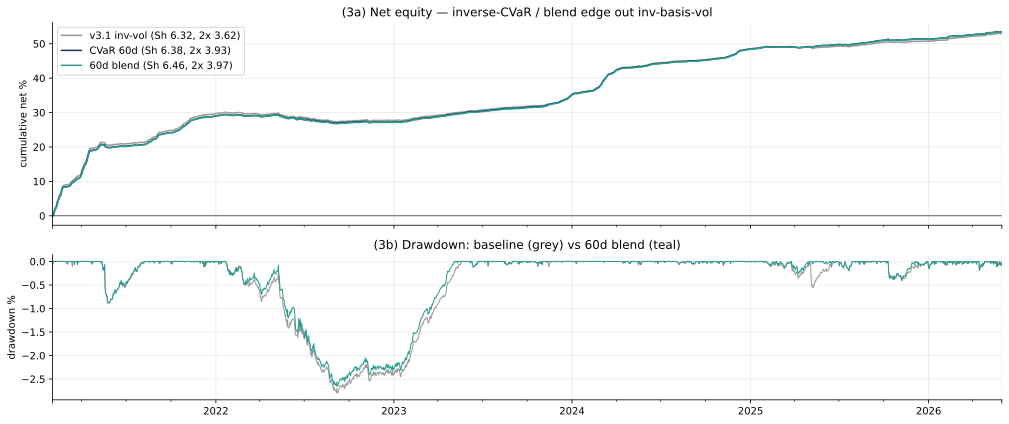

In [5]:
r_cv, r_bl = v31_book(cv60s), blend_book(cv60s, invvol)
fig,(a1,a2) = plt.subplots(2,1,figsize=(14,6),sharex=True,gridspec_kw={'height_ratios':[1.4,1]})
for lab_,r,c in [(f"v3.1 inv-vol (Sh {base['1.0x']['sharpe']:.2f}, 2x {base['2.0x']['sharpe']:.2f})",base,GREY),
                 (f"CVaR 60d (Sh {r_cv['1.0x']['sharpe']:.2f}, 2x {r_cv['2.0x']['sharpe']:.2f})",r_cv,NAVY),
                 (f"60d blend (Sh {r_bl['1.0x']['sharpe']:.2f}, 2x {r_bl['2.0x']['sharpe']:.2f})",r_bl,TEAL)]:
    eq(r).plot(ax=a1,color=c,lw=1.5,label=lab_)
a1.axhline(0,color='k',lw=0.6); a1.set_ylabel('cumulative net %'); a1.legend(); a1.set_title('(3a) Net equity — inverse-CVaR / blend edge out inv-basis-vol')
for r,c in [(base,GREY),(r_bl,TEAL)]:
    H.drawdown(r['net']).mul(100).plot(ax=a2,color=c,lw=1.0)
a2.set_ylabel('drawdown %'); a2.set_title('(3b) Drawdown: baseline (grey) vs 60d blend (teal)'); plt.tight_layout(); plt.show()

## 4. Robustness — the window band and the winsor clip

The win is not a single lucky knob. **Window sweep (30-120d):** the improvement is a *plateau* over
45-90d (peaking ≈60d), with 2×-cost Sharpe above baseline across the band; only 30d (too few
observations to estimate a 5% tail — k≈2 points) and 120d (stale) fail to help. **Clip sweep:** any
sensible winsor (0.8-0.95) gives essentially the same result; only *no* winsorization (1.0) degrades
it, as a couple of near-zero-tail names then dominate the book.

      IS Sh  IS 2x  TEST 2x  IS DD%  turn
30d    6.07   3.23     3.99   -2.92  22.2
45d    6.31   3.76     4.80   -2.80  19.5
60d    6.38   3.93     5.19   -2.52  18.6
90d    6.33   3.75     5.31   -2.55  17.3
120d   6.25   3.67     5.15   -2.46  16.6


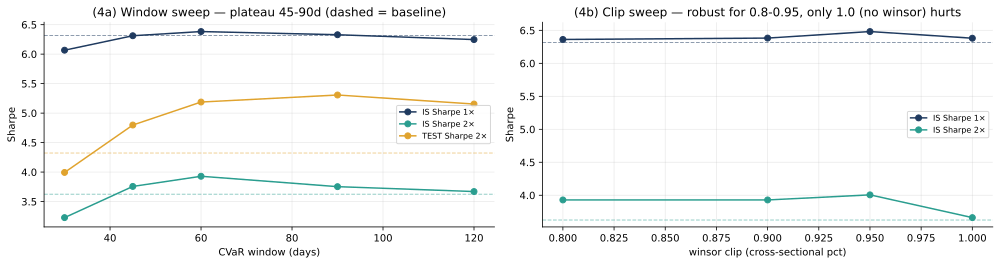

In [6]:
WINS=[30,45,60,90,120]
ws = pd.DataFrame({f'{w}d':{'IS Sh':v31_book(cvar_size(w))['1.0x']['sharpe'],'IS 2x':v31_book(cvar_size(w))['2.0x']['sharpe'],
                            'TEST 2x':v31_book(cvar_size(w),mask=te)['2.0x']['sharpe'],
                            'IS DD%':round(v31_book(cvar_size(w))['1.0x']['max_drawdown']*100,2),
                            'turn':v31_book(cvar_size(w))['1.0x']['ann_turnover']} for w in WINS}).T
fig,(a1,a2)=plt.subplots(1,2,figsize=(14,3.8))
a1.plot(WINS, ws['IS Sh'], '-o', color=NAVY, label='IS Sharpe 1×')
a1.plot(WINS, ws['IS 2x'], '-o', color=TEAL, label='IS Sharpe 2×')
a1.plot(WINS, ws['TEST 2x'], '-o', color=AMBER, label='TEST Sharpe 2×')
a1.axhline(base['1.0x']['sharpe'],color=NAVY,ls='--',lw=1,alpha=0.5); a1.axhline(base['2.0x']['sharpe'],color=TEAL,ls='--',lw=1,alpha=0.5)
a1.axhline(H.book(base['W'],P,COSTS,mask=te,warmup_days=30)['2.0x']['sharpe'],color=AMBER,ls='--',lw=1,alpha=0.5)
a1.set_xlabel('CVaR window (days)'); a1.set_ylabel('Sharpe'); a1.legend(fontsize=8); a1.set_title('(4a) Window sweep — plateau 45-90d (dashed = baseline)')
CLIPS=[0.80,0.90,0.95,1.00]
cs = pd.DataFrame({f'{c:.2f}':{'IS Sh':v31_book(cvar_size(60,c))['1.0x']['sharpe'],'IS 2x':v31_book(cvar_size(60,c))['2.0x']['sharpe']} for c in CLIPS}).T
a2.plot(CLIPS, cs['IS Sh'], '-o', color=NAVY, label='IS Sharpe 1×')
a2.plot(CLIPS, cs['IS 2x'], '-o', color=TEAL, label='IS Sharpe 2×')
a2.axhline(base['1.0x']['sharpe'],color=NAVY,ls='--',lw=1,alpha=0.5); a2.axhline(base['2.0x']['sharpe'],color=TEAL,ls='--',lw=1,alpha=0.5)
a2.set_xlabel('winsor clip (cross-sectional pct)'); a2.set_ylabel('Sharpe'); a2.legend(fontsize=8); a2.set_title('(4b) Clip sweep — robust for 0.8-0.95, only 1.0 (no winsor) hurts')
print(ws.round(2).to_string()); plt.tight_layout(); plt.show()

## Verdict — modest SHIP-CANDIDATE (60d CVaR, blended with inv-vol)

- **Passes the ship bar, modestly.** Inverse-CVaR sizing (60d) lifts net Sharpe (6.32→6.38), **2×-cost
  Sharpe (3.62→3.93)**, shrinks maxDD (−2.8→−2.5%) and *lowers* turnover (20.5→18.6) — all in-sample —
  and holds out-of-sample (TEST Sharpe 7.5→7.7, 2× 4.3→5.2). The **50/50 blend** with inv-basis-vol is
  marginally better still and more robust (IS Sh 6.46, 2× 3.97; TEST Sh 8.0, 2× 5.4) — the two risk
  views are complementary, so blend rather than replace.
- **Mechanism.** CVaR measures the *downside tail of the full pair return* (funding flips + basis
  blowouts together), which is the risk that actually costs money; inverse-basis-vol is symmetric and
  funding-blind. Reweighting toward thin-left-tail names cuts realized drawdown and, because those
  names are also steadier, cuts turnover (hence the 2× gain). Part of the 2× improvement is that lower
  churn; part is a genuine small tail improvement (CVaR₉₅ and maxDD both improve).
- **Robust** across the 45-90d window (plateau, peak ≈60d; 30d too noisy to estimate a tail, 120d
  stale) and the 0.8-0.95 winsor clip.
- **Caveats.** Effect size is small; single OOS period; CVaR₅% on 60 daily obs is still a noisy tail
  estimate (the winsor is load-bearing — do not run un-clipped). Best treated as a blend, not a
  replacement, of the existing inv-vol sizing. Productionizing is a separate decision.